# Lab 2: K-Nearest Neighbors and Radius Neighbors Classification

**Student:** Rajasekhar Reddy Kayyam  
**Course:** MSCS 634 – Advanced Big Data & Data Mining  
**Assignment:** Lab 2 – Wine Dataset Classification

**Objective:** Compare K-Nearest Neighbors (KNN) and Radius Neighbors (RNN) classifiers on the scikit-learn Wine Dataset, using the specified neighbor counts and radii. Report test accuracy and interpret the effect of the parameters.

**Reproducibility:** The split uses `random_state=42` and `stratify=y`. Both methods use Euclidean distance on the **original, unscaled features** so that the required radius values (350–600) retain their intended meaning. This makes features with larger numerical scales more influential; scaling would require a different radius range.

## 1. Imports and dataset exploration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier
from sklearn.metrics import accuracy_score

wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name="target")
print("Dataset shape:", X.shape)
print("Classes:", list(wine.target_names))
print("Feature names:", wine.feature_names)
print("Class distribution:")
print(y.value_counts().sort_index().rename(index=dict(enumerate(wine.target_names))))
display(X.head())
display(X.describe().T.round(2))

Dataset shape: (178, 13)
Classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]
Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Class distribution:
target
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


The dataset contains 178 samples, 13 chemical features, and three wine classes. Class counts are 59, 71, and 48. Some features, notably `proline`, have much larger numerical values than others, which matters for distance-based classifiers.

## 2. Split into 80% training and 20% testing

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training class counts:", y_train.value_counts().sort_index().to_dict())
print("Testing class counts:", y_test.value_counts().sort_index().to_dict())

Training samples: 142
Testing samples: 36
Training class counts: {0: 47, 1: 57, 2: 38}
Testing class counts: {0: 12, 1: 14, 2: 10}


## 3. K-Nearest Neighbors (KNN)

In [3]:
k_values = [1, 5, 11, 15, 21]
knn_results = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k, metric="euclidean")
    model.fit(X_train, y_train)
    accuracy = accuracy_score(y_test, model.predict(X_test))
    knn_results.append({"k": k, "accuracy": accuracy})
knn_df = pd.DataFrame(knn_results)
display(knn_df.assign(accuracy_percent=lambda d: (100*d.accuracy).round(2)))

,k,accuracy,accuracy_percent
0,1,0.777778,77.78
1,5,0.805556,80.56
2,11,0.805556,80.56
3,15,0.805556,80.56
4,21,0.805556,80.56


## 4. Radius Neighbors (RNN)

Radius Neighbors uses all training samples within a fixed Euclidean radius. The `outlier_label="most_frequent"` setting supplies a defined prediction if a test point has no neighbors within its radius. We also count such cases to make the handling transparent. For this particular split and radii, no test points have zero neighbors.

In [4]:
radius_values = [350, 400, 450, 500, 550, 600]
rnn_results = []
for radius in radius_values:
    model = RadiusNeighborsClassifier(
        radius=radius, metric="euclidean", outlier_label="most_frequent"
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    no_neighbor_count = sum(len(ids) == 0 for ids in model.radius_neighbors(X_test, return_distance=False))
    rnn_results.append({
        "radius": radius,
        "accuracy": accuracy_score(y_test, predictions),
        "test_points_without_neighbors": no_neighbor_count
    })
rnn_df = pd.DataFrame(rnn_results)
display(rnn_df.assign(accuracy_percent=lambda d: (100*d.accuracy).round(2)))

,radius,accuracy,test_points_without_neighbors,accuracy_percent
0,350,0.722222,0,72.22
1,400,0.694444,0,69.44
2,450,0.694444,0,69.44
3,500,0.694444,0,69.44
4,550,0.666667,0,66.67
5,600,0.666667,0,66.67


## 5. Accuracy visualizations

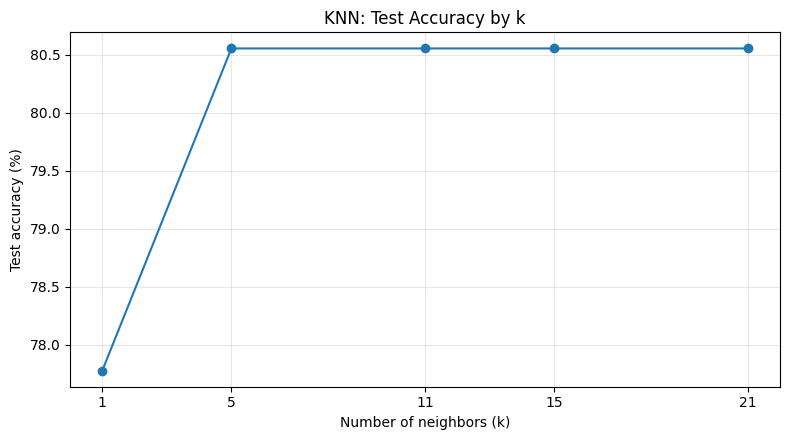

In [5]:
plt.figure(figsize=(8, 4.5))
plt.plot(knn_df["k"], 100 * knn_df["accuracy"], marker="o")
plt.xticks(k_values)
plt.xlabel("Number of neighbors (k)")
plt.ylabel("Test accuracy (%)")
plt.title("KNN: Test Accuracy by k")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("knn_accuracy.png", dpi=160)
plt.show()

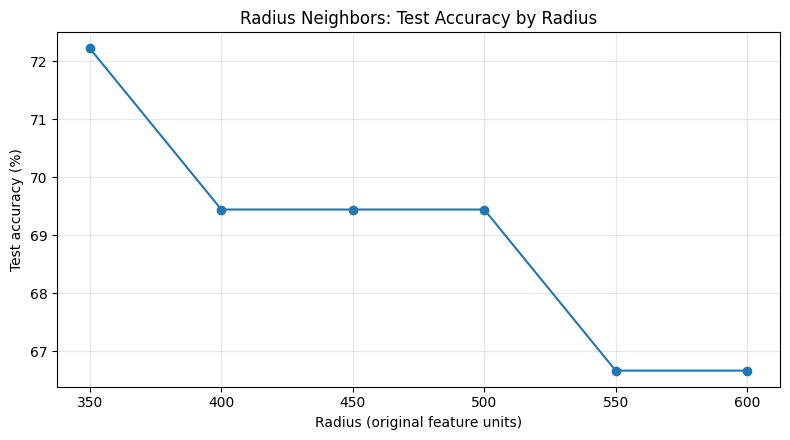

In [6]:
plt.figure(figsize=(8, 4.5))
plt.plot(rnn_df["radius"], 100 * rnn_df["accuracy"], marker="o")
plt.xticks(radius_values)
plt.xlabel("Radius (original feature units)")
plt.ylabel("Test accuracy (%)")
plt.title("Radius Neighbors: Test Accuracy by Radius")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("rnn_accuracy.png", dpi=160)
plt.show()

## 6. Comparison and interpretation

In [7]:
print("KNN results:")
display(knn_df.assign(accuracy_percent=(100*knn_df.accuracy).round(2)))
print("Radius Neighbors results:")
display(rnn_df.assign(accuracy_percent=(100*rnn_df.accuracy).round(2)))
print(f"Best KNN accuracy: {100*knn_df.accuracy.max():.2f}%")
print(f"Best RNN accuracy: {100*rnn_df.accuracy.max():.2f}%")

KNN results:


,k,accuracy,accuracy_percent
0,1,0.777778,77.78
1,5,0.805556,80.56
2,11,0.805556,80.56
3,15,0.805556,80.56
4,21,0.805556,80.56


Radius Neighbors results:


,radius,accuracy,test_points_without_neighbors,accuracy_percent
0,350,0.722222,0,72.22
1,400,0.694444,0,69.44
2,450,0.694444,0,69.44
3,500,0.694444,0,69.44
4,550,0.666667,0,66.67
5,600,0.666667,0,66.67


Best KNN accuracy: 80.56%
Best RNN accuracy: 72.22%


### Observations

- **KNN:** Accuracy is **77.78%** at `k=1`, then **80.56%** for each of `k=5, 11, 15, 21`. Increasing `k` beyond 5 does not improve accuracy for this test split.
- **Radius Neighbors:** Accuracy is **72.22%** at radius 350, **69.44%** at radii 400, 450, and 500, and **66.67%** at radii 550 and 600. Larger radii can include increasingly distant samples from other classes, reducing discrimination.
- **Comparison:** The best KNN configuration exceeds the best Radius Neighbors configuration by **8.33 percentage points** on this held-out test set. This is an observation for one fixed split, not proof that KNN is universally superior.

### When to choose each method

**KNN** is useful when a fixed number of neighbors is desirable and local sample density varies. **Radius Neighbors** can be preferable when a physically meaningful distance threshold exists and the number of relevant nearby observations should adapt to density; sparse regions may require explicit outlier handling.

### Limitations and decisions

The experiment intentionally keeps features **unscaled** to match the assigned radius values. Since Wine features differ substantially in magnitude, raw Euclidean distance can be dominated by large-scale variables. Standardization may improve comparisons but requires retuning radii on the scaled distance scale. More reliable model selection would use cross-validation on training data, with the test set reserved for final evaluation. No hyperparameters were chosen using the test labels for a subsequent final evaluation.

## References

Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html

Scikit-learn developers. (n.d.). *Wine recognition dataset*. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html

Scikit-learn developers. (n.d.). *Nearest neighbors*. https://scikit-learn.org/stable/modules/neighbors.html